# SimCLR on CIFAR-10 — Projection-Head Ablation

Reproduction of **SimCLR** (Chen et al., 2020, *A Simple Framework for Contrastive Learning of Visual Representations*) at CIFAR-10 compute scale.

**Experiments**
1. **SimCLR + non-linear projection head** (default) — pretrain, then linear-eval on $h$ (and, for reference, on $z=g(h)$).
2. **SimCLR without projection head** ($g=\text{Identity}$, loss applied directly on $h\in\mathbb{R}^{512}$) — pretrain, then linear-eval on $h$.
3. **Supervised ResNet-18** trained end-to-end (upper-bound baseline).
4. *(extra, free)* **Randomly-initialised frozen encoder** + linear probe (lower-bound sanity check).


## 2. Scale Adaptation (what differs from the paper)

| Aspect | Paper (main results) | This notebook |
|---|---|---|
| **Dataset** | ImageNet, 1.28M images, 224×224 | **CIFAR-10**, 50k train images, 32×32 |
| **Backbone** | ResNet-50 ($h\in\mathbb{R}^{2048}$) | **ResNet-18** ($h\in\mathbb{R}^{512}$), CIFAR stem (3×3 conv, no max-pool) |
| **Batch size** | $N=4096$ ($2N=8192$ views) | **$N=256$** ($2N=512$ views) |
| **Pretraining epochs** | 100 – 1000 | **40** (configurable 30–50) |
| **Optimiser** | LARS, lr $=0.3\times N/256$, cosine decay, wd $10^{-6}$ | **Adam**, lr $10^{-3}$, wd $10^{-6}$, cosine decay (LARS is unnecessary at small batch size) |
| **Temperature** | 0.1 – 0.5 (tuned) | **0.5** (Appendix B.9) |
| **Augmentations** | crop + flip + colour jitter (0.8·s) + grayscale + blur | crop(0.2–1) + flip + colour jitter(0.4,0.4,0.4,0.1; p=0.8) + grayscale (p=0.2), **no blur** |
| **Linear eval** | 90 epochs on frozen $h$, with augmentation | **20 epochs** on pre-extracted frozen $h$ (no augmentation, standardised features) |
| **Mixed precision** | – | fp16 autocast for the encoder; loss in fp32 |

Because of the ~25× fewer epochs and ~16× smaller batch (fewer negatives), **absolute accuracies will be far below the paper's**; the goal is to reproduce the **relative ordering** (non-linear head > no head; supervised > self-supervised at this budget).

## 3. Setup & Configuration

In [ ]:
import os, time, math, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader

# ------------------------------ configuration ------------------------------
QUICK_MODE = False          # True -> 2 epochs everywhere (smoke test, ~5 min)

class CFG:
    seed            = 42
    batch_size      = 256               # N  (=> 2N = 512 views per step)
    pretrain_epochs = 40               # 15-30 recommended
    linear_epochs   = 20                # 15-20 recommended
    sup_epochs      = 20
    tau             = 0.5               # NT-Xent temperature (Appendix B.9)
    proj_dim        = 128
    lr              = 1e-3              # Adam (LARS not needed at this scale)
    weight_decay    = 1e-6
    num_workers     = 0                 # Set to 0 to fix the DataLoader worker exited unexpectedly error
    data_root       = "./data"
    use_amp         = True

if QUICK_MODE:
    CFG.pretrain_epochs = CFG.linear_epochs = CFG.sup_epochs = 2

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(CFG.seed)
device = "cuda" if torch.cuda.is_available() else "cpu"
CFG.use_amp = CFG.use_amp and device == "cuda"
torch.backends.cudnn.benchmark = True
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))
if device == "cpu":
    print("WARNING: no GPU detected. Enable one via Runtime > Change runtime type, or use QUICK_MODE.")
print({k: v for k, v in vars(CFG).items() if not k.startswith("_")})

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda (Tesla T4)
{'seed': 42, 'batch_size': 256, 'pretrain_epochs': 40, 'linear_epochs': 20, 'sup_epochs': 20, 'tau': 0.5, 'proj_dim': 128, 'lr': 0.001, 'weight_decay': 1e-06, 'num_workers': 0, 'data_root': './data', 'use_amp': True}


In [ ]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

class SimCLRDataTransform:
    """Returns two independently augmented views (x_i, x_j) of the same PIL image."""
    def __init__(self, size=32):
        self.aug = T.Compose([
            T.RandomResizedCrop(size, scale=(0.2, 1.0)),                      # Inception-style crop
            T.RandomHorizontalFlip(p=0.5),
            T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),        # colour distortion
            T.RandomGrayscale(p=0.2),
            T.ToTensor(),
            T.Normalize(CIFAR_MEAN, CIFAR_STD),
        ])
    def __call__(self, x):
        return self.aug(x), self.aug(x)

plain_tf = T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])      # for feature extraction / test
sup_train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                          T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])  # standard supervised aug

simclr_train_ds = CIFAR10(CFG.data_root, train=True,  download=True, transform=SimCLRDataTransform())
feat_train_ds   = CIFAR10(CFG.data_root, train=True,  download=True, transform=plain_tf)
test_ds         = CIFAR10(CFG.data_root, train=False, download=True, transform=plain_tf)
sup_train_ds    = CIFAR10(CFG.data_root, train=True,  download=True, transform=sup_train_tf)

dl_kw = dict(num_workers=CFG.num_workers, pin_memory=(device == "cuda"),
             persistent_workers=(CFG.num_workers > 0))
# drop_last=True keeps 2N constant (clean negatives count) for every step
simclr_loader = DataLoader(simclr_train_ds, batch_size=CFG.batch_size, shuffle=True, drop_last=True, **dl_kw)
feat_train_loader = DataLoader(feat_train_ds, batch_size=1024, shuffle=False, **dl_kw)
test_loader       = DataLoader(test_ds,       batch_size=1024, shuffle=False, **dl_kw)
sup_loader        = DataLoader(sup_train_ds, batch_size=128, shuffle=True, drop_last=True, **dl_kw)
print(f"train: {len(simclr_train_ds)} | test: {len(test_ds)} | SimCLR steps/epoch: {len(simclr_loader)}")

train: 50000 | test: 10000 | SimCLR steps/epoch: 195


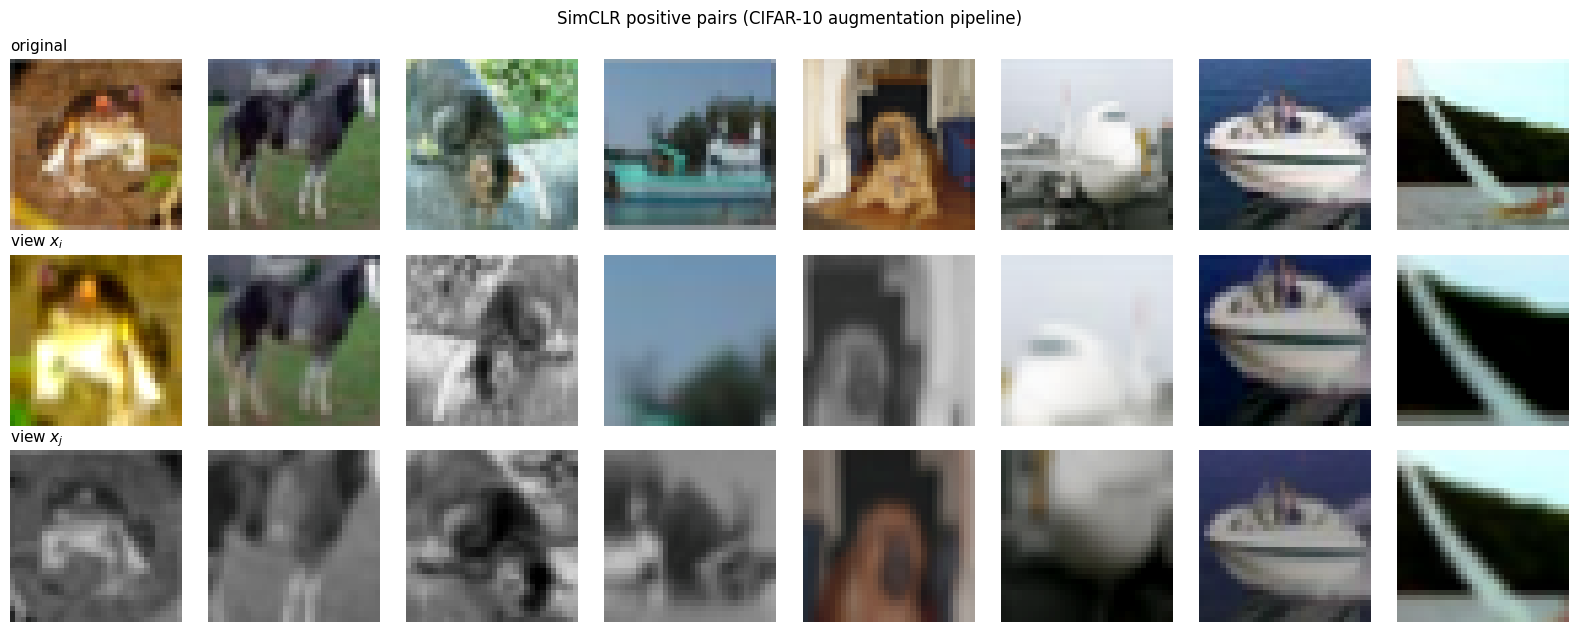

In [ ]:
# Visualise positive pairs: each row = original | view i | view j
raw_ds = CIFAR10(CFG.data_root, train=True, download=False, transform=None)
tfm = SimCLRDataTransform()
mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1); std_t = torch.tensor(CIFAR_STD).view(3, 1, 1)
unnorm = lambda t: (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for c in range(8):
    img, _ = raw_ds[c * 37]
    xi, xj = tfm(img)
    for r, im in enumerate([np.asarray(img) / 255.0, unnorm(xi), unnorm(xj)]):
        axes[r, c].imshow(im); axes[r, c].axis("off")
for r, name in enumerate(["original", "view $x_i$", "view $x_j$"]):
    axes[r, 0].set_title(name, loc="left", fontsize=11)
plt.suptitle("SimCLR positive pairs (CIFAR-10 augmentation pipeline)"); plt.tight_layout(); plt.show()

## 5. Model: CIFAR ResNet-18 encoder $f$ + projection head $g$

Stem modified per Appendix B.9: 3×3 conv, stride 1, padding 1, no bias; initial max-pool removed → feature maps stay $32\times32$ in layer1. `fc` is replaced by `Identity`, so the encoder output is the 512-d $h$ after adaptive average pooling.

In [ ]:
def make_resnet18_cifar():
    m = torchvision.models.resnet18(weights=None)
    m.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)  # 7x7/2 -> 3x3/1
    m.maxpool = nn.Identity()                                                   # remove 2x max-pool
    m.fc = nn.Identity()                                                        # output h in R^512
    return m

class SimCLR(nn.Module):
    def __init__(self, use_head=True, proj_dim=128, feat_dim=512):
        super().__init__()
        self.encoder = make_resnet18_cifar()                                    # f(.)
        self.head = (nn.Sequential(                                             # g(.)  non-linear MLP head
                        nn.Linear(feat_dim, feat_dim),
                        nn.BatchNorm1d(feat_dim),
                        nn.ReLU(inplace=True),
                        nn.Linear(feat_dim, proj_dim))
                     if use_head else nn.Identity())                            # ablation: g = Identity
    def forward(self, x):
        h = self.encoder(x)
        z = self.head(h)
        return h, z

for flag in (True, False):
    m = SimCLR(use_head=flag, proj_dim=CFG.proj_dim)
    h, z = m(torch.randn(4, 3, 32, 32))
    print(f"use_head={flag!s:5} | h: {tuple(h.shape)} | z: {tuple(z.shape)} | params: {sum(p.numel() for p in m.parameters())/1e6:.2f}M")

use_head=True  | h: (4, 512) | z: (4, 128) | params: 11.50M
use_head=False | h: (4, 512) | z: (4, 512) | params: 11.17M


## 6. Vectorised NT-Xent Loss

Layout: `z = [view_1 of images 0..N-1 ; view_2 of images 0..N-1]` ($2N\times d$). The positive of row $i$ is row $(i+N)\bmod 2N$.
1. $L_2$-normalise → `z @ z.T` is the full cosine-similarity matrix.
2. Divide by $\tau$.
3. Mask the diagonal ($k=i$) with a large negative value so it has zero softmax mass.
4. `cross_entropy(logits, positive_index)` = $\frac1{2N}\sum_i \ell_{i,\text{pos}(i)}$, computed with log-sum-exp stabilisation internally.

We also return the in-batch **contrastive top-1 accuracy** (is the positive the most similar of the $2N-1$ candidates?) as a training diagnostic. The loss is always computed in fp32.

In [ ]:
def nt_xent_loss(z, tau=0.5):
    """z: (2N, d) with rows [0:N] = view 1, [N:2N] = view 2. Returns (loss, top-1 contrastive acc)."""
    z = F.normalize(z.float(), dim=1)                                  # L2-normalise (fp32)
    two_n = z.size(0); n = two_n // 2
    logits = (z @ z.t()) / tau                                         # (2N, 2N) cosine sim / tau
    self_mask = torch.eye(two_n, dtype=torch.bool, device=z.device)
    logits = logits.masked_fill(self_mask, -1e9)                       # exclude k == i from the denominator
    targets = torch.cat([torch.arange(n, two_n), torch.arange(0, n)]).to(z.device)
    loss = F.cross_entropy(logits, targets)                            # = mean of l_{i,j} (stable logsumexp)
    with torch.no_grad():
        acc = (logits.argmax(dim=1) == targets).float().mean()
    return loss, acc

# ---------- unit test against a naive, loop-based implementation of the paper's equation ----------
def nt_xent_naive(z, tau):
    z = F.normalize(z, dim=1); two_n = z.size(0); n = two_n // 2; total = 0.0
    for i in range(two_n):
        j = (i + n) % two_n
        num = torch.exp(z[i] @ z[j] / tau)
        den = sum(torch.exp(z[i] @ z[k] / tau) for k in range(two_n) if k != i)
        total = total - torch.log(num / den)
    return total / two_n

torch.manual_seed(0)
zt = torch.randn(16, 32)
a, _ = nt_xent_loss(zt, 0.5); b = nt_xent_naive(zt, 0.5)
print(f"vectorised = {a.item():.6f} | naive = {b.item():.6f} | |diff| = {abs(a-b).item():.2e}")
assert abs(a - b) < 1e-4, "vectorised NT-Xent does not match the reference formula!"

# aligned views should give a much lower loss than random embeddings
base = torch.randn(8, 32)
aligned, _ = nt_xent_loss(torch.cat([base, base + 0.01 * torch.randn_like(base)]), 0.5)
random_, _ = nt_xent_loss(torch.randn(16, 32), 0.5)
print(f"aligned-pairs loss = {aligned.item():.4f}  <  random-embeddings loss = {random_.item():.4f}")
assert aligned < random_
print("NT-Xent unit tests passed ✔")

vectorised = 2.918498 | naive = 2.918498 | |diff| = 2.38e-07
aligned-pairs loss = 1.1132  <  random-embeddings loss = 2.4458
NT-Xent unit tests passed ✔


## 7. Self-supervised Pretraining Routine

Both SimCLR variants share *exactly* the same training code, data order seed, optimiser and schedule — the **only** difference is `use_head`.

In [ ]:
def pretrain_simclr(use_head, epochs, name):
    set_seed(CFG.seed)                                                  # identical init/data seed across variants
    model = SimCLR(use_head=use_head, proj_dim=CFG.proj_dim).to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.use_amp)
    hist = {"loss": [], "acc": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run_loss = run_acc = 0.0; nb = 0
        for (x1, x2), _ in simclr_loader:
            x = torch.cat([x1, x2], dim=0).to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CFG.use_amp):
                _, z = model(x)
            loss, acc = nt_xent_loss(z, CFG.tau)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            run_loss += loss.item(); run_acc += acc.item(); nb += 1
        sched.step()
        hist["loss"].append(run_loss / nb); hist["acc"].append(run_acc / nb)
        print(f"[{name}] epoch {ep:3d}/{epochs} | loss {hist['loss'][-1]:.4f} | contrastive top-1 {hist['acc'][-1]*100:5.1f}% "
              f"| lr {sched.get_last_lr()[0]:.2e} | {time.time()-t0:6.0f}s")
    torch.save(model.state_dict(), f"/content/simclr_{name}.pt" if os.path.isdir("/content") else f"simclr_{name}.pt")
    return model, hist

### 7.1 Experiment 1 — SimCLR with non-linear projection head (default)

In [ ]:
model_head, hist_head = pretrain_simclr(use_head=True, epochs=CFG.pretrain_epochs, name="nonlinear_head")

[nonlinear_head] epoch   1/40 | loss 5.2597 | contrastive top-1  14.0% | lr 9.98e-04 |    117s
[nonlinear_head] epoch   2/40 | loss 5.0099 | contrastive top-1  27.3% | lr 9.94e-04 |    233s
[nonlinear_head] epoch   3/40 | loss 4.9170 | contrastive top-1  35.4% | lr 9.86e-04 |    350s
[nonlinear_head] epoch   4/40 | loss 4.8557 | contrastive top-1  42.0% | lr 9.76e-04 |    467s
[nonlinear_head] epoch   5/40 | loss 4.8153 | contrastive top-1  47.9% | lr 9.62e-04 |    584s
[nonlinear_head] epoch   6/40 | loss 4.7813 | contrastive top-1  52.4% | lr 9.46e-04 |    699s
[nonlinear_head] epoch   7/40 | loss 4.7612 | contrastive top-1  55.6% | lr 9.26e-04 |    816s
[nonlinear_head] epoch   8/40 | loss 4.7405 | contrastive top-1  58.0% | lr 9.05e-04 |    933s
[nonlinear_head] epoch   9/40 | loss 4.7301 | contrastive top-1  59.7% | lr 8.80e-04 |   1050s
[nonlinear_head] epoch  10/40 | loss 4.7131 | contrastive top-1  61.8% | lr 8.54e-04 |   1167s
[nonlinear_head] epoch  11/40 | loss 4.7063 | cont

### 7.2 Experiment 2 — SimCLR without projection head (ablation: NT-Xent directly on $h\in\mathbb{R}^{512}$)

In [ ]:
model_nohead, hist_nohead = pretrain_simclr(use_head=False, epochs=CFG.pretrain_epochs, name="no_head")

[no_head] epoch   1/40 | loss 5.5489 | contrastive top-1   8.4% | lr 9.98e-04 |    115s
[no_head] epoch   2/40 | loss 5.2975 | contrastive top-1  16.2% | lr 9.94e-04 |    230s
[no_head] epoch   3/40 | loss 5.1792 | contrastive top-1  22.3% | lr 9.86e-04 |    345s
[no_head] epoch   4/40 | loss 5.1196 | contrastive top-1  26.5% | lr 9.76e-04 |    460s
[no_head] epoch   5/40 | loss 5.0668 | contrastive top-1  29.6% | lr 9.62e-04 |    576s
[no_head] epoch   6/40 | loss 5.0275 | contrastive top-1  33.4% | lr 9.46e-04 |    693s
[no_head] epoch   7/40 | loss 4.9931 | contrastive top-1  36.2% | lr 9.26e-04 |    810s
[no_head] epoch   8/40 | loss 4.9712 | contrastive top-1  38.3% | lr 9.05e-04 |    926s
[no_head] epoch   9/40 | loss 4.9464 | contrastive top-1  40.3% | lr 8.80e-04 |   1042s
[no_head] epoch  10/40 | loss 4.9297 | contrastive top-1  42.1% | lr 8.54e-04 |   1157s
[no_head] epoch  11/40 | loss 4.9120 | contrastive top-1  44.4% | lr 8.25e-04 |   1272s
[no_head] epoch  12/40 | loss 4.

## 8. Linear Evaluation Protocol

The encoder $f$ is **frozen** (eval mode, no gradients) and the head $g$ is **discarded**. We extract $h=f(x)$ once for train/test (no augmentation), standardise with *train* mean/std (an affine, non-learned transform — the classifier remains a single linear layer), and train **one `nn.Linear(512, 10)`** with cross-entropy for `linear_epochs` epochs.

Reported accuracy is the **final-epoch** test accuracy (no checkpoint selection on the test set). For Experiment 1 we additionally probe $z=g(h)$ to reproduce the paper's "$h$ is better than $g(h)$" observation.

In [ ]:
@torch.no_grad()
def extract_features(model, loader):
    """Returns (h, z, y) with the encoder frozen. For no-head models z == h."""
    model.eval(); H, Z, Y = [], [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CFG.use_amp):
            h, z = model(x)
        H.append(h.float()); Z.append(z.float()); Y.append(y.to(device))
    return torch.cat(H), torch.cat(Z), torch.cat(Y)

def linear_eval(Ftr, ytr, Fte, yte, epochs=20, bs=256, lr=1e-2, wd=1e-6, seed=0):
    torch.manual_seed(seed)
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-6      # train statistics only
    Ftr, Fte = (Ftr - mu) / sd, (Fte - mu) / sd
    clf = nn.Linear(Ftr.size(1), 10).to(device)                              # single linear layer
    opt = torch.optim.Adam(clf.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    n = Ftr.size(0); hist = {"train_loss": [], "test_acc": []}
    for ep in range(epochs):
        perm = torch.randperm(n, device=device); tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(clf(Ftr[idx]), ytr[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item() * idx.numel()
        sched.step()
        with torch.no_grad():
            acc = (clf(Fte).argmax(1) == yte).float().mean().item() * 100
        hist["train_loss"].append(tot / n); hist["test_acc"].append(acc)
    return hist["test_acc"][-1], hist

results, lin_hist = {}, {}

def run_linear_eval(model, name, key="h"):
    Htr, Ztr, ytr = extract_features(model, feat_train_loader)
    Hte, Zte, yte = extract_features(model, test_loader)
    Ftr, Fte = (Htr, Hte) if key == "h" else (Ztr, Zte)
    acc, hist = linear_eval(Ftr, ytr, Fte, yte, epochs=CFG.linear_epochs)
    results[name] = acc; lin_hist[name] = hist
    print(f"{name:45s} -> linear-eval test acc: {acc:.2f}%  (feature dim {Ftr.size(1)})")

# sanity lower bound: a *randomly initialised*, never-trained encoder
set_seed(CFG.seed)
rand_model = SimCLR(use_head=False).to(device).to(memory_format=torch.channels_last)
run_linear_eval(rand_model, "Random-init encoder (h)")
del rand_model

run_linear_eval(model_head,   "SimCLR + non-linear head: eval on h")
run_linear_eval(model_head,   "SimCLR + non-linear head: eval on z=g(h)", key="z")
run_linear_eval(model_nohead, "SimCLR, no head: eval on h")

Random-init encoder (h)                       -> linear-eval test acc: 42.21%  (feature dim 512)
SimCLR + non-linear head: eval on h           -> linear-eval test acc: 79.83%  (feature dim 512)
SimCLR + non-linear head: eval on z=g(h)      -> linear-eval test acc: 74.10%  (feature dim 128)
SimCLR, no head: eval on h                    -> linear-eval test acc: 74.46%  (feature dim 512)


## 9. Experiment 3 — Supervised Baseline (upper bound)

Same CIFAR-ResNet-18 backbone + `Linear(512,10)`, trained end-to-end with labels and cross-entropy for `sup_epochs` epochs (SGD + Nesterov, OneCycle LR, standard crop/flip augmentation).

In [ ]:
def train_supervised(epochs):
    set_seed(CFG.seed)
    enc = make_resnet18_cifar()
    model = nn.Sequential(enc, nn.Linear(512, 10)).to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, epochs=epochs, steps_per_epoch=len(sup_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.use_amp)
    hist = {"loss": [], "test_acc": []}; t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0; nb = 0
        for x, y in sup_loader:
            x = x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last); y = y.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CFG.use_amp):
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        model.eval(); correct = 0
        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(device).contiguous(memory_format=torch.channels_last); y = y.to(device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CFG.use_amp):
                    correct += (model(x).argmax(1) == y).sum().item()
        hist["loss"].append(tot / nb); hist["test_acc"].append(100 * correct / len(test_ds))
        print(f"[supervised] epoch {ep:2d}/{epochs} | loss {hist['loss'][-1]:.4f} | test acc {hist['test_acc'][-1]:.2f}% | {time.time()-t0:5.0f}s")
    return model, hist

sup_model, sup_hist = train_supervised(CFG.sup_epochs)
results["Supervised ResNet-18 (end-to-end)"] = sup_hist["test_acc"][-1]

[supervised] epoch  1/20 | loss 1.5431 | test acc 54.13% |    34s
[supervised] epoch  2/20 | loss 1.0514 | test acc 62.93% |    68s
[supervised] epoch  3/20 | loss 0.8125 | test acc 72.99% |   102s
[supervised] epoch  4/20 | loss 0.6697 | test acc 77.42% |   136s
[supervised] epoch  5/20 | loss 0.5837 | test acc 75.65% |   170s
[supervised] epoch  6/20 | loss 0.5127 | test acc 78.69% |   204s
[supervised] epoch  7/20 | loss 0.4573 | test acc 81.93% |   238s
[supervised] epoch  8/20 | loss 0.4244 | test acc 81.22% |   272s
[supervised] epoch  9/20 | loss 0.3926 | test acc 82.17% |   307s
[supervised] epoch 10/20 | loss 0.3670 | test acc 83.12% |   341s
[supervised] epoch 11/20 | loss 0.3430 | test acc 83.52% |   375s
[supervised] epoch 12/20 | loss 0.3221 | test acc 84.81% |   409s
[supervised] epoch 13/20 | loss 0.3048 | test acc 86.80% |   443s
[supervised] epoch 14/20 | loss 0.2766 | test acc 87.39% |   478s
[supervised] epoch 15/20 | loss 0.2438 | test acc 89.24% |   512s
[supervise

## 10. Results: Comparison Table, Loss Curves & Accuracy Plot

In [ ]:
paper_trend = {
    "Random-init encoder (h)":                      "— (sanity lower bound)",
    "SimCLR, no head: eval on h":                   "Fig. 8: worst — >10 pts below non-linear head",
    "SimCLR + non-linear head: eval on h":          "Fig. 8: best — non-linear > linear > none",
    "SimCLR + non-linear head: eval on z=g(h)":     "Fig. 8 / Tab. 3: z is >10 pts worse than h (info discarded)",
    "Supervised ResNet-18 (end-to-end)":            "Upper bound; SimCLR approaches it only at huge scale/long training",
}
order = ["Random-init encoder (h)", "SimCLR, no head: eval on h", "SimCLR + non-linear head: eval on h",
         "SimCLR + non-linear head: eval on z=g(h)", "Supervised ResNet-18 (end-to-end)"]
dim = {"Random-init encoder (h)": 512, "SimCLR, no head: eval on h": 512, "SimCLR + non-linear head: eval on h": 512,
       "SimCLR + non-linear head: eval on z=g(h)": CFG.proj_dim, "Supervised ResNet-18 (end-to-end)": 512}
df = pd.DataFrame({
    "Method / representation": order,
    "Feature dim": [dim[k] for k in order],
    "Pretrain epochs": [0, CFG.pretrain_epochs, CFG.pretrain_epochs, CFG.pretrain_epochs, CFG.sup_epochs],
    "Observed test acc (%)": [round(results[k], 2) for k in order],
    "Paper trend (ImageNet, ResNet-50)": [paper_trend[k] for k in order],
})
pd.set_option("display.max_colwidth", 80, "display.width", 200)
print("=" * 150); print("SimCLR on CIFAR-10 — structured comparison (ResNet-18, N=256, tau=0.5)"); print("=" * 150)
print(df.to_string(index=False)); print("=" * 150)

gap = results["SimCLR + non-linear head: eval on h"] - results["SimCLR, no head: eval on h"]
gap_z = results["SimCLR + non-linear head: eval on h"] - results["SimCLR + non-linear head: eval on z=g(h)"]
print(f"\nProjection-head effect  (h with head  -  h without head) : {gap:+.2f} pts")
print(f"Pre- vs post-head       (h  -  z=g(h))  within Exp. 1     : {gap_z:+.2f} pts")
print("Paper trend: non-linear head improves h by >10 pts over no head (ImageNet, 800+ epochs); "
      "at 40 epochs on CIFAR-10 the gap is typically smaller, but its sign should match.")
try: df.to_csv("results_table.csv", index=False)
except Exception: pass

SimCLR on CIFAR-10 — structured comparison (ResNet-18, N=256, tau=0.5)
                 Method / representation  Feature dim  Pretrain epochs  Observed test acc (%)                                  Paper trend (ImageNet, ResNet-50)
                 Random-init encoder (h)          512                0                  42.21                                             — (sanity lower bound)
              SimCLR, no head: eval on h          512               40                  74.46                      Fig. 8: worst — >10 pts below non-linear head
     SimCLR + non-linear head: eval on h          512               40                  79.83                          Fig. 8: best — non-linear > linear > none
SimCLR + non-linear head: eval on z=g(h)          128               40                  74.10        Fig. 8 / Tab. 3: z is >10 pts worse than h (info discarded)
       Supervised ResNet-18 (end-to-end)          512               20                  93.22 Upper bound; SimCLR approaches

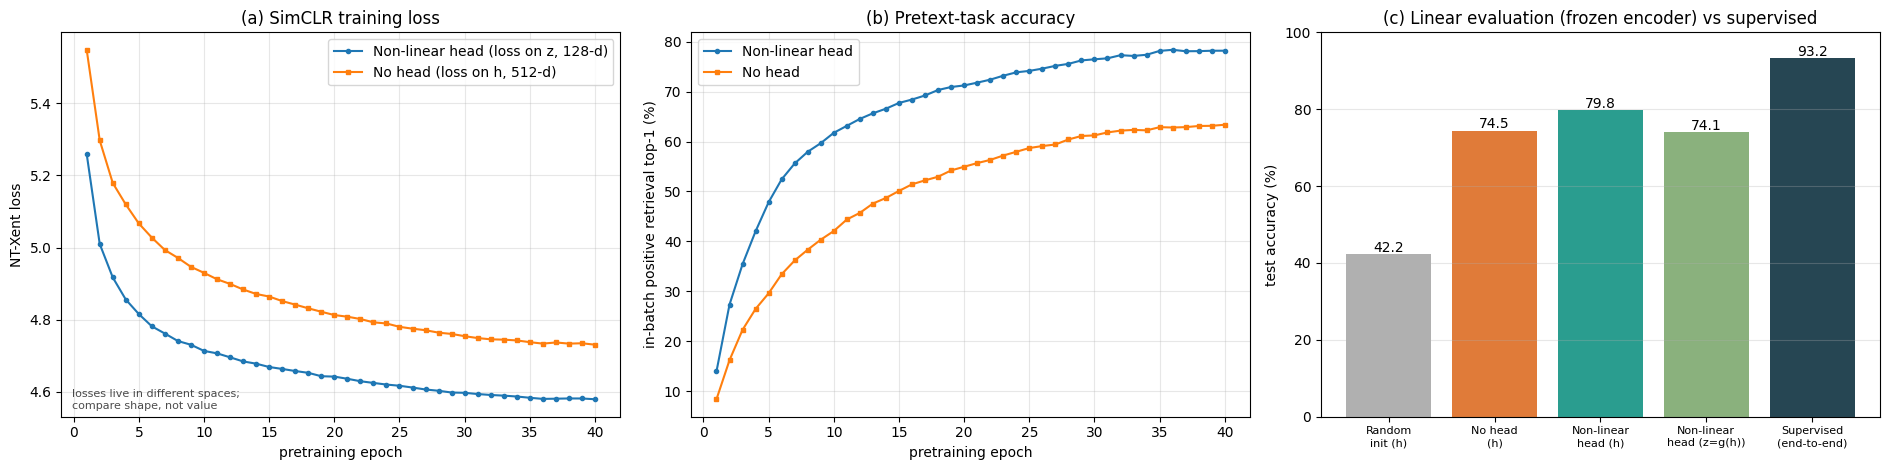

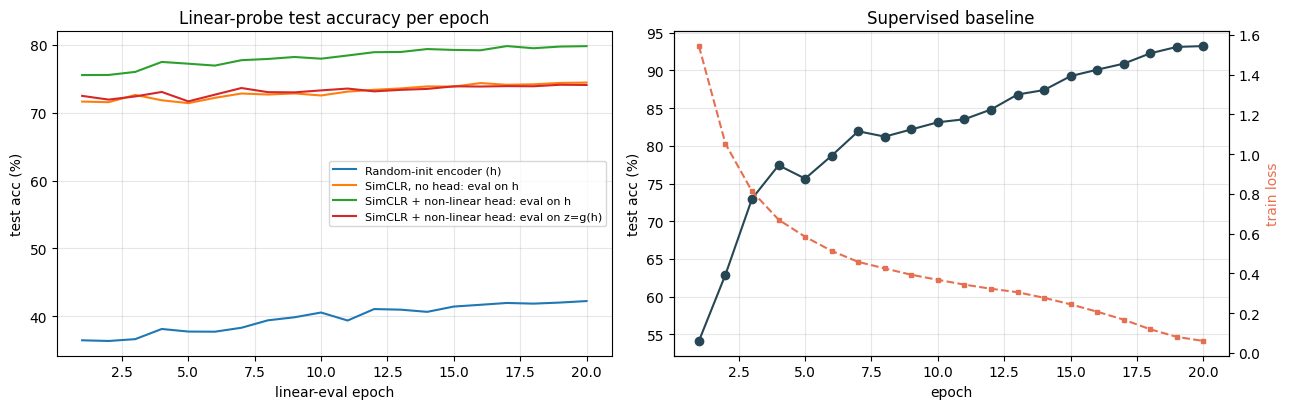

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ep = np.arange(1, CFG.pretrain_epochs + 1)

# (a) NT-Xent training loss
ax[0].plot(ep, hist_head["loss"],   "o-", ms=3, label="Non-linear head (loss on z, 128-d)")
ax[0].plot(ep, hist_nohead["loss"], "s-", ms=3, label="No head (loss on h, 512-d)")
ax[0].set(xlabel="pretraining epoch", ylabel="NT-Xent loss", title="(a) SimCLR training loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].text(0.02, 0.02, "losses live in different spaces;\ncompare shape, not value", transform=ax[0].transAxes, fontsize=8, alpha=.7)

# (b) contrastive top-1 accuracy
ax[1].plot(ep, np.array(hist_head["acc"]) * 100,   "o-", ms=3, label="Non-linear head")
ax[1].plot(ep, np.array(hist_nohead["acc"]) * 100, "s-", ms=3, label="No head")
ax[1].set(xlabel="pretraining epoch", ylabel="in-batch positive retrieval top-1 (%)", title="(b) Pretext-task accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)

# (c) linear evaluation accuracies
labels = ["Random\ninit (h)", "No head\n(h)", "Non-linear\nhead (h)", "Non-linear\nhead (z=g(h))", "Supervised\n(end-to-end)"]
vals = [results[k] for k in order]
bars = ax[2].bar(labels, vals, color=["#b0b0b0", "#e07b39", "#2a9d8f", "#8ab17d", "#264653"])
for b, v in zip(bars, vals): ax[2].text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}", ha="center", fontsize=10)
ax[2].set(ylabel="test accuracy (%)", title="(c) Linear evaluation (frozen encoder) vs supervised", ylim=(0, 100)); ax[2].grid(axis="y", alpha=.3)
ax[2].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig("simclr_results.png", dpi=150); plt.show()

# linear-probe learning curves + supervised curve
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k in order[:4]:
    ax[0].plot(range(1, CFG.linear_epochs + 1), lin_hist[k]["test_acc"], label=k)
ax[0].set(xlabel="linear-eval epoch", ylabel="test acc (%)", title="Linear-probe test accuracy per epoch"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(range(1, CFG.sup_epochs + 1), sup_hist["test_acc"], "o-", color="#264653", label="test acc")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test acc (%)"); ax[1].set_title("Supervised baseline"); ax[1].grid(alpha=.3)
ax2 = ax[1].twinx(); ax2.plot(range(1, CFG.sup_epochs + 1), sup_hist["loss"], "s--", color="#e76f51", ms=3); ax2.set_ylabel("train loss", color="#e76f51")
plt.tight_layout(); plt.show()